In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [84]:
# Read the Variants data from MongoDB
# The connection string may change based on AWS EC2 allocation
import pymongo
client = pymongo.MongoClient("mongodb://ec2-52-91-54-55.compute-1.amazonaws.com:27017/")

# Connect to the database "CROO"
db = client["CROO"]

# Connect to the collection "Variants" and load the data
collection = db["Variants"]
# find the documents with a matching Run_Batch field of "Expanded_Baseline"
batch = "Firesat_Baseline"
variants_df = pd.DataFrame(list(collection.find({"Run_Batch": batch})))
print(len(variants_df))
variants_df.head()

120


,_id,Variant_name,Run_Batch,Variant_path,Simulation,FSW,date_created,date_loaded,Simulation_rows,FSW_rows,Simulation_columns,FSW_columns,description
0,68b12485935ba08fa02036c8,1_0.0_0,Firesat_Baseline,Firesat_Baseline/FireSat_baseline_updated_1_0....,SIM_Output.csv,FSW_Output.csv,2025-08-29T03:54:34.216196,2025-08-29T03:54:45.984822,602,602,69,134,
1,68b12492935ba08fa0203b7d,1_36.0_0,Firesat_Baseline,Firesat_Baseline/FireSat_baseline_updated_1_36...,SIM_Output.csv,FSW_Output.csv,2025-08-29T03:54:46.089648,2025-08-29T03:54:58.827963,602,602,69,134,
2,68b1249f935ba08fa0204032,1_72.0_0,Firesat_Baseline,Firesat_Baseline/FireSat_baseline_updated_1_72...,SIM_Output.csv,FSW_Output.csv,2025-08-29T03:54:58.928442,2025-08-29T03:55:11.794282,602,602,69,134,
3,68b124ab935ba08fa02044e7,1_108.0_0,Firesat_Baseline,Firesat_Baseline/FireSat_baseline_updated_1_10...,SIM_Output.csv,FSW_Output.csv,2025-08-29T03:55:11.900084,2025-08-29T03:55:23.651383,602,602,69,134,
4,68b124b7935ba08fa020499c,1_144.0_0,Firesat_Baseline,Firesat_Baseline/FireSat_baseline_updated_1_14...,SIM_Output.csv,FSW_Output.csv,2025-08-29T03:55:23.744846,2025-08-29T03:55:35.496401,602,602,69,134,


In [23]:
variants_df = pd.read_csv("./data/raw/attack_rwa/variants_data.csv")

In [24]:
variants_df.shape

(600, 13)

In [4]:
variants_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   _id                 120 non-null    object 
 1   Variant_name        120 non-null    object 
 2   Run_Batch           120 non-null    object 
 3   Variant_path        120 non-null    object 
 4   Simulation          120 non-null    object 
 5   FSW                 120 non-null    object 
 6   date_created        120 non-null    object 
 7   date_loaded         120 non-null    object 
 8   Simulation_rows     120 non-null    int64  
 9   FSW_rows            120 non-null    int64  
 10  Simulation_columns  120 non-null    int64  
 11  FSW_columns         120 non-null    int64  
 12  description         0 non-null      float64
dtypes: float64(1), int64(4), object(8)
memory usage: 12.3+ KB


In [25]:
# write the DataFrame to a local CSV file
variants_df.to_csv("./data/raw/attack_rwa/variants_data.csv", index=False)

In [26]:
variants_df['Scenario'] = 'attack_rwa'

In [ ]:
# Read the FSW data from MongoDB
fsw_collection = db["FSW"]
fsw_df = pd.DataFrame(list(fsw_collection.find({"Run_Batch": batch})))

In [27]:
import os

In [28]:
variants_df['data_file'] =variants_df.apply(lambda row: f"./data/raw/{row['Scenario']}/fsw_data_{row['Variant_name']}.csv", axis=1)

In [29]:
def get_data_and_label(variants_df):
    df = pd.DataFrame()
    # For each datafile, load the data and append it to the training_df
    for index, row in variants_df.iterrows():
        data_file = row['data_file']
        if os.path.exists(data_file):
            data = pd.read_csv(data_file)
            data['Scenario'] = row['Scenario']
            data['Run_Batch_Variant'] = data['Run_Batch'] + '_' + data['Variant']
            # Always Label the first 302 rows as baseline and the rest as the Scenario
            data["result_label"] = data["Scenario"]
            data.loc[data.index < 302, "result_label"] = "baseline"
            df = pd.concat([df, data], ignore_index=True)
    return df

In [30]:
fsw_df = get_data_and_label(variants_df)
fsw_df.shape

(361200, 142)

In [31]:
import math
# Create Longitude(deg) from Longitude(rad) and Latitude(deg) from Latitude(rad)
fsw_df['Longitude(deg)'] = fsw_df['Longitude(rad)'] * (180 / math.pi)
fsw_df['Latitude(deg)'] = fsw_df['Latitude(rad)'] * (180 / math.pi)

In [32]:
# Add a column to fsw_df for time_delay, it is the second token in the Variant string
fsw_df['TimeDelay'] = fsw_df['Variant'].apply(lambda x: float(x.split('_')[1]) if '_' in x else 0.0)

# Add a column to fsw_df for intensity of the attack, it is the last token in the Variant string
#fsw_df['AttackIntensity'] = fsw_df['Variant'].apply(lambda x: float(x.split('_')[-1]) if '_' in x else 0.0)

In [33]:
# Add a column to the variants for month, it is the first token in the Variant_name string
variants_df['Month'] = variants_df['Variant_name'].apply(lambda x: x.split('_')[0] if '_' in x else '')

# Add a column to the variants for time_delay, it is the second token in the Variant_name string
variants_df['TimeDelay'] = variants_df['Variant_name'].apply(lambda x: float(x.split('_')[1]) if '_' in x else 0.0)

In [ ]:
# Plot the distribution of variants per month and per attack intensity and show all 11 intensities.
plt.figure(figsize=(16, 6))
sns.countplot(data=variants_df, x='Month', palette='viridis')
plt.title('Distribution of Variants per Month and Attack Intensity')
plt.xlabel('Month')
plt.ylabel('Count')
plt.tight_layout()


In [52]:
import cartopy.crs as ccrs
def plot_orbits(df, title):
    # Create figure
    fig, ax = plt.subplots(figsize=(20, 12), subplot_kw={'projection': ccrs.PlateCarree()})

    # Add background map
    ax.stock_img()

    # Create a colormap from unique strings
    unique_categories = list(set(df['result_label']))  # Get unique labels
    cmap = plt.colormaps['tab10']  # Use the new colormap access method
    #color_map = {cat: cmap(i / len(unique_categories)) for i, cat in enumerate(unique_categories)}  # Map labels to colors
    #print(color_map)
    color_map = {'baseline': 'orange', 'attack_rwa': 'blue'}
    colors = [color_map[cat] for cat in df['result_label']]  

    # Scatter plot
    sc = ax.scatter(
        df['Longitude(deg)'], df['Latitude(deg)'],
        s=.1,  # Marker size
        color=colors,
        alpha=0.7
    )

    # Create a colormap from unique strings
    # unique_categories = list(set(df['Variant']))  # Get unique labels

    # for cat in unique_categories:
    #     record = df[df['Variant'] == cat].iloc[300] # Assuming the attack point is at index 360
    #     ax.scatter(
    #         record['Longitude(deg)'], record['Latitude(deg)'],
    #         s=50,  # Marker size
    #         color='red',  # Use a fixed color for the attack point
    #         alpha=0.7,
    #         label=cat
    #     )

    # Add title
    plt.title(title)

    # Show the plot
    plt.show()

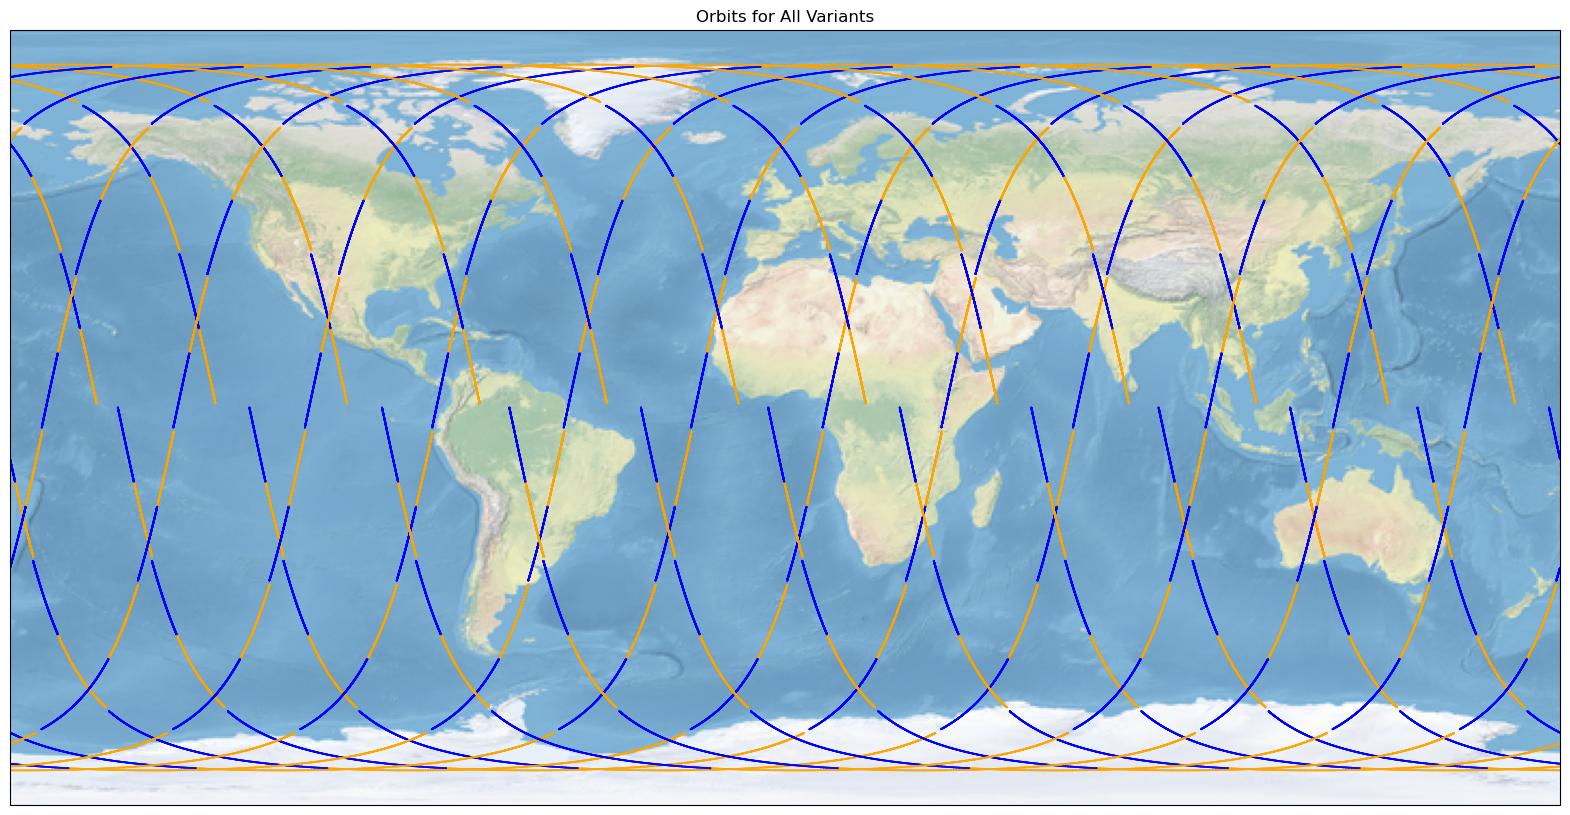

In [53]:
plot_orbits(fsw_df, "Orbits for All Variants")

In [19]:
def plot_mid_points(df, title):
    # Plot the first record from each variant on a map
    fig, ax = plt.subplots(figsize=(20, 12), subplot_kw={'projection': ccrs.PlateCarree()})
    ax.stock_img()

    # Create a colormap from unique strings
    unique_categories = list(set(df['Variant']))  # Get unique labels

    for cat in unique_categories:
        record = df[df['Variant'] == cat].iloc[300] # Assuming the attack point is at index 360
        ax.scatter(
            record['Longitude(deg)'], record['Latitude(deg)'],
            s=50,  # Marker size
            color='red',  # Use a fixed color for the attack point
            alpha=0.7,
            label=cat
        )

    # Add title
    plt.title(title)

    fig.show()

C:\Users\JoeDavis\AppData\Local\Temp\ipykernel_27168\3732292284.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


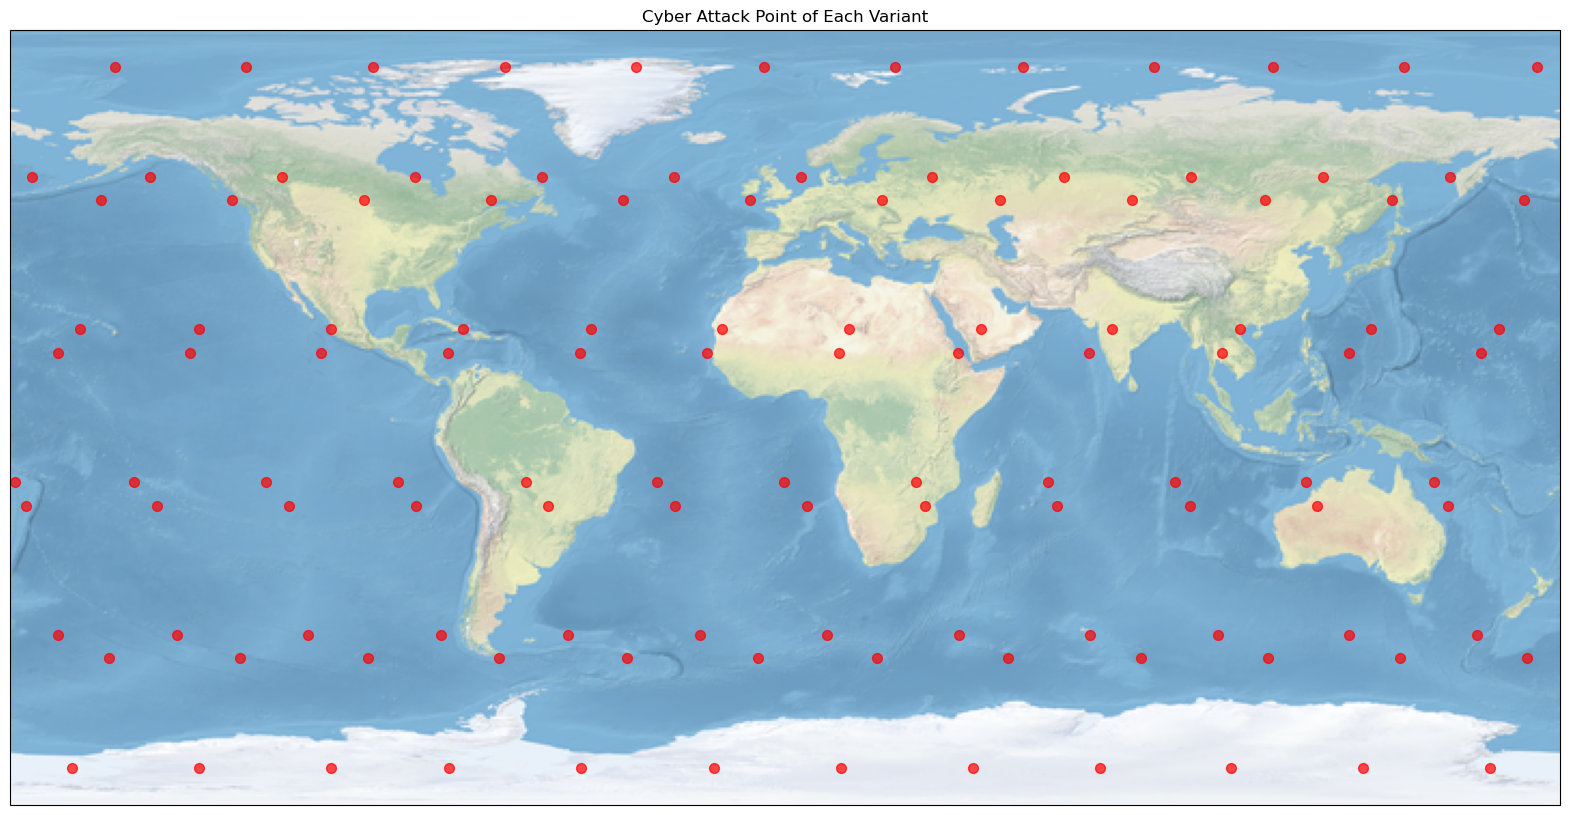

In [20]:
# Plot the starting points for each variant
plot_mid_points(fsw_df, "Cyber Attack Point of Each Variant")

In [ ]:
# Create a function to make a grid of plots for each field in dataframe vs FswTime(sec) where attack intensity is different colored lines
def plot_fields_vs_time(df, title):
    fields = df.columns.tolist()
    fields.remove("FswTime(sec)")  # Remove the time field from the list
    fields.remove("_id")  # Remove the attack intensity field from the list
    num_fields = len(fields)
    
    fig, axes = plt.subplots(nrows=(num_fields + 2) // 3, ncols=3, figsize=(20, 4 * ((num_fields + 2) // 3)))
    axes = axes.flatten()  # Flatten the axes array for easy indexing

    for i, field in enumerate(fields):
        sns.lineplot(data=df, x="FswTime(sec)", y=field, hue="AttackIntensity", ax=axes[i])
        axes[i].set_title(f"{field} vs FswTime(sec)")
        axes[i].set_xlabel("FswTime(sec)")
        axes[i].set_ylabel(field)

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(title)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # Adjust layout to make room for the title
    plt.show()

In [ ]:
# Plot the fields in fsw of the variants in month 1 with time delay 0.0
month1_df = fsw_df[(fsw_df['CurrentMonth(month)'] == 1) & (fsw_df['TimeDelay'] == 0.0)]
print(len(month1_df))
month1_df.head()
plot_fields_vs_time(month1_df, "Fields in FSW Data for Month 1 with Time Delay 0.0")

In [ ]:
ecss_columns = ["FswTime(sec)","SemiMajorAxis(m)","Eccentricity(1)","Inclination(deg)","Raan(deg)","ArgPerigee(deg)","TrueAnomaly(deg)","Mode()",
                "UTC", "Latitude(rad)","Longitude(rad)", "Altitude(m)", "StateOfCharge__BAT(A*hr)", "PercentSoC__BAT(1)", "DepthOfDischarge__BAT(1)",
                "IncomingCharge__BAT(W)", "InEclipse()", 
                "SunBetaAngle(rad)", "SunUnit_B[0](1)", "SunUnit_B[1](1)", "SunUnit_B[2](1)"
                ]

ecss_df = fsw_df[ecss_columns]

In [ ]:
# Create a version of FSW with only first 300 records for each variant
fsw_baseline_df = fsw_df.groupby("Variant").head(300)

# get the ecss data for the first 300 records of each variant
ecss_baseline_df = fsw_baseline_df[ecss_columns]
# Create a Correlation Matrix for ecss data with only first 300 records
ecss_baseline_corr = ecss_baseline_df.corr()
# Create a heatmap for the correlation matrix
plt.figure(figsize=(16, 10))
sns.heatmap(ecss_baseline_corr, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})
plt.title("Correlation Matrix for ECSS Data (Baseline)")

In [ ]:
# Create the same thing for everything after the first 300 records
fsw_attack_df = fsw_df.groupby("Variant").tail(fsw_df.shape[0] - 300)
# get the ecss data for everything after the first 300 records of each variant
ecss_attack_df = fsw_attack_df[ecss_columns]
# Create a Correlation Matrix for ecss data after the first 300 records
ecss_attack_corr = ecss_attack_df.corr()
# Create a heatmap for the correlation matrix
plt.figure(figsize=(16, 10))
sns.heatmap(ecss_attack_corr, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})
plt.title("Correlation Matrix for ECSS Data (Attack)")

In [ ]:
# Group the FSW data by Variant
fsw_grouped = fsw_df.groupby("Variant")

# Write each FSW group to a separate CSV file
for variant_name, group in fsw_grouped:
    group.to_csv(f"./data/raw/baseline/fsw_data_{variant_name}.csv", index=False)